# Synthetic Recovery of Time-Dependent Thermal Diffusivity

This notebook verifies the time-dependent inverse framework by recovering a prescribed synthetic diffusivity history, `alpha_true(t)`, from synthetic temperature observations.

The workflow follows the synthetic recovery verification described in `inversion_YB/02_soil_thermal_inversion_repor_YB_v2.pdf` and `inversion_YB/synthetic_recovery_section.tex`:

1. prescribe a smooth time-dependent thermal diffusivity, `alpha_true(t)`;
2. generate synthetic temperature observations with the same implicit Crank-Nicolson heat model;
3. add controlled measurement noise;
4. recover `alpha_rec(t)` using the time-dependent inverse solver;
5. quantify the recovery by correlation and relative error.

The true diffusivity is used only to generate the synthetic data. It is not supplied to the inverse solver.

In [31]:
from pathlib import Path
import string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import matplotlib.ticker as ticker
from IPython.display import display

from soil_inverse import HeatGrid
from soil_inverse.timevarying import solve_time_dependent_alpha
from soil_inverse.timevarying import _forward  # synthetic-data generator using the same theta-method engine

plt.rcParams["text.usetex"] = False
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.family"] = "Times New Roman"

alphabet = list(string.ascii_lowercase)

def text_alphabet(handel, w, xx=0.05, yy=0.98):
    handel.text(
        xx,
        yy,
        f"({w})",
        transform=handel.transAxes,
        ha="left",
        va="top",
        fontsize=18,
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="none"),
    )


## 1. Synthetic-Recovery Parameters

The synthetic test uses the same vertical sensor depths and refined-grid resolution as the updated soil inverse workflow. To test whether the inverse model can recover a repeatedly varying diffusivity, the prescribed thermal diffusivity is extended over several idealized cycles and is estimated in log-space on a 3-hour control grid with temporal smoothness regularization. Time is reported as elapsed hours from the beginning of the synthetic experiment rather than as a calendar date.

In [32]:
OUTPUT_DIR = Path("00_output_figures")
OUTPUT_DIR.mkdir(exist_ok=True)
SYNTH_OUT_DIR = OUTPUT_DIR / "04_synthetic_recovery_time_dependent_alpha"
SYNTH_OUT_DIR.mkdir(parents=True, exist_ok=True)

DEPTHS_M = np.array([0.25, 0.50, 0.75, 1.00], dtype=float)
DT_SECONDS = 600.0
RESAMPLE_INTERVAL = "10min"

# Calendar timestamps are retained only for the solver's internal control-grid helper.
# Figures and tables report elapsed time [hr], which is the meaningful time coordinate
# for this synthetic verification experiment.
SYNTH_START = pd.Timestamp("2000-01-01 00:00")
ALPHA_PERIOD_HOURS = 48.0
N_ALPHA_CYCLES = 4
SYNTH_HOURS = ALPHA_PERIOD_HOURS * N_ALPHA_CYCLES
N_STEPS = int(SYNTH_HOURS * 1800 / DT_SECONDS) + 1
TIMES = pd.date_range(SYNTH_START, periods=N_STEPS, freq=RESAMPLE_INTERVAL)
TIME_HOURS = np.arange(N_STEPS, dtype=float) * DT_SECONDS / 3600.0

CELLS_PER_GAP = 5
THETA_CN = 0.5
CONTROL_HOURS = 3.0
NOISE_FRACTION = 0.01
RANDOM_SEED = 7

ALPHA_PRIOR = 1.0e-6
ALPHA_INITIAL = 1.0e-6
ALPHA_BOUNDS = (1.0e-8, 1.0e-5)
BETA_SMOOTH = 1.0
BETA_PRIOR = 0.1
MAX_ITER = 600

FIG_RECOVERY = SYNTH_OUT_DIR / "synthetic_recovery_alpha_t.jpg"
FIG_TEMPERATURE = SYNTH_OUT_DIR / "synthetic_temperature_observation_prediction_residual.jpg"
CSV_SYNTHETIC = SYNTH_OUT_DIR / "synthetic_recovery_timeseries.csv"
CSV_METRICS = SYNTH_OUT_DIR / "synthetic_recovery_metrics.csv"

# Convenience copy matching the report figure name.
FIG_RECOVERY_COPY = OUTPUT_DIR / "synthetic_recovery_alpha_t.jpg"

## 2. Prescribe True Alpha and Synthetic Boundaries

The prescribed `alpha_true(t)` is smooth, positive, and cyclic. The forcing is expressed using elapsed time so that the case represents a generic verification experiment rather than a specific field date. Synthetic top and bottom boundary temperatures are generated as time-varying Dirichlet data so that the forward problem resembles the field-data setup.

In [33]:
grid = HeatGrid(
    DEPTHS_M,
    dt_seconds=DT_SECONDS,
    cells_per_gap=CELLS_PER_GAP,
    theta=THETA_CN,
)

# Synthetic boundary temperatures [degC].
# These retain a diurnal component, while the deeper boundary varies more slowly.
top_boundary = 29.0 + 3.6 * np.sin(2.0 * np.pi * (TIME_HOURS - 6.0) / 24.0)
top_boundary += 0.7 * np.sin(2.0 * np.pi * TIME_HOURS / 12.0)
bottom_boundary = 28.4 + 0.4 * np.sin(2.0 * np.pi * (TIME_HOURS - 18.0) / 96.0)

# Prescribed true time-dependent thermal diffusivity [m^2/s].
# A multi-cycle signal is used to test whether the inverse method recovers repeated
# increases and decreases, not merely one isolated event.
alpha_true = 8.2e-7
alpha_true += 2.3e-7 * np.sin(2.0 * np.pi * (TIME_HOURS - 8.0) / ALPHA_PERIOD_HOURS)
alpha_true += 0.7e-7 * np.sin(2.0 * np.pi * TIME_HOURS / (ALPHA_PERIOD_HOURS / 2.0))

pulse_width_hours = 12
pulse_centers = (np.arange(N_ALPHA_CYCLES, dtype=float) + 0.62) * ALPHA_PERIOD_HOURS
for center_hour in pulse_centers:
    alpha_true += 1.0e-7 * np.exp(-0.5 * ((TIME_HOURS - center_hour) / pulse_width_hours) ** 2)

alpha_true = np.clip(alpha_true, 2.0e-7, 1.6e-6)

print(grid)
print(f"synthetic span = {SYNTH_HOURS:.0f} hr, alpha cycles = {N_ALPHA_CYCLES}")
print(f"r(alpha=1e-6) = {grid.r(1.0e-6):.6f}")
print(f"alpha_true range = {alpha_true.min():.3e} to {alpha_true.max():.3e} m^2/s")

HeatGrid(n_cells=15, dz_m=0.0500, dt_seconds=600, theta=0.5)
synthetic span = 192 hr, alpha cycles = 4
r(alpha=1e-6) = 0.240000
alpha_true range = 5.794e-07 to 1.114e-06 m^2/s


## 3. Generate Noisy Synthetic Observations

The forward model uses per-transition diffusivity. For the synthetic data, the transition diffusivity is the average of `alpha_true` at the two adjacent time samples. The generated interior sensor temperatures are then perturbed with Gaussian noise.

In [34]:
alpha_transition = 0.5 * (alpha_true[:-1] + alpha_true[1:])
alpha_face_steps = np.repeat(alpha_transition[:, None], grid.n_cells, axis=1)

initial_profile = np.array([top_boundary[0], 28.8, 28.6, bottom_boundary[0]], dtype=float)
u0 = np.interp(grid.nodes_m[1:-1], DEPTHS_M, initial_profile)

state_history = _forward(
    grid,
    alpha_face_steps,
    top_boundary,
    bottom_boundary,
    u0,
    theta=THETA_CN,
)
synthetic_interior_clean = state_history[:, grid._obs_local]

rng = np.random.default_rng(RANDOM_SEED)
noise_sigma = NOISE_FRACTION * float(np.std(synthetic_interior_clean))
synthetic_interior_noisy = synthetic_interior_clean + rng.normal(
    loc=0.0,
    scale=noise_sigma,
    size=synthetic_interior_clean.shape,
)

synthetic_temps = np.column_stack([
    top_boundary,
    synthetic_interior_noisy[:, 0],
    synthetic_interior_noisy[:, 1],
    bottom_boundary,
])
synthetic_temps_clean = np.column_stack([
    top_boundary,
    synthetic_interior_clean[:, 0],
    synthetic_interior_clean[:, 1],
    bottom_boundary,
])

print(f"synthetic temperature shape = {synthetic_temps.shape}")
print(f"noise sigma = {noise_sigma:.4f} degC")
print(f"T2 clean/noisy std = {np.std(synthetic_interior_clean[:, 0]):.4f} / {np.std(synthetic_interior_noisy[:, 0]):.4f} degC")


synthetic temperature shape = (577, 4)
noise sigma = 0.0041 degC
T2 clean/noisy std = 0.5321 / 0.5321 degC


## 4. Recover Time-Dependent Alpha

The inverse solver estimates `alpha(t)` from the noisy interior observations and prescribed top/bottom boundary temperatures. The unknowns are log-alpha values on the control grid; they are linearly interpolated to each forward-model transition.

,correlation_alpha_true_recovered,median_relative_error_percent,mean_relative_error_percent,rmse_alpha_m2_s,rmse_temperature_degC,noise_sigma_degC,cost,cost_data,cost_reg,n_iter,n_grad_eval,success,synthetic_hours,alpha_period_hours,n_alpha_cycles,control_hours,beta_smooth,beta_prior
0,0.998396,0.622737,1.224088,1.348972e-08,0.005703,0.004108,0.173521,0.018764,0.154757,48,51,True,192.0,48.0,4,3.0,1.0,0.1


saved timeseries: 00_output_figures/04_synthetic_recovery_time_dependent_alpha/synthetic_recovery_timeseries.csv
saved metrics: 00_output_figures/04_synthetic_recovery_time_dependent_alpha/synthetic_recovery_metrics.csv


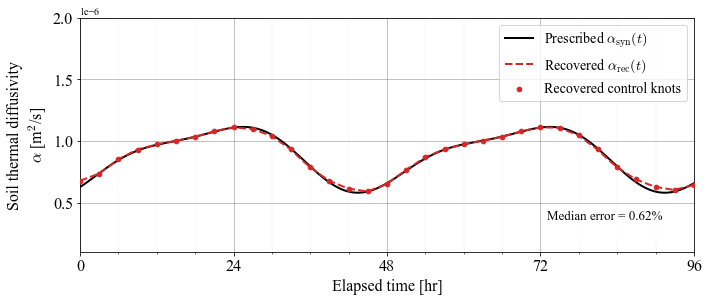

saved recovery figure: 00_output_figures/04_synthetic_recovery_time_dependent_alpha/synthetic_recovery_alpha_t.jpg


In [35]:
result = solve_time_dependent_alpha(
    synthetic_temps,
    grid,
    TIMES,
    control_hours=CONTROL_HOURS,
    beta_smooth=BETA_SMOOTH,
    beta_prior=BETA_PRIOR,
    alpha_prior=ALPHA_PRIOR,
    alpha_initial=ALPHA_INITIAL,
    bounds=ALPHA_BOUNDS,
    theta=THETA_CN,
    n_layers=1,
    max_iter=MAX_ITER,
)

alpha_recovered = result.alpha_t
prediction_interior = result.prediction
residual_interior = prediction_interior - synthetic_interior_noisy

relative_error = np.abs(alpha_recovered - alpha_true) / alpha_true
corr_alpha = float(np.corrcoef(alpha_true, alpha_recovered)[0, 1])
median_error_percent = float(np.median(relative_error) * 100.0)
mean_error_percent = float(np.mean(relative_error) * 100.0)
rmse_alpha = float(np.sqrt(np.mean((alpha_recovered - alpha_true) ** 2)))
rmse_temperature = float(np.sqrt(np.mean(residual_interior ** 2)))

metrics = pd.DataFrame([{
    "correlation_alpha_true_recovered": corr_alpha,
    "median_relative_error_percent": median_error_percent,
    "mean_relative_error_percent": mean_error_percent,
    "rmse_alpha_m2_s": rmse_alpha,
    "rmse_temperature_degC": rmse_temperature,
    "noise_sigma_degC": noise_sigma,
    "cost": result.cost,
    "cost_data": result.cost_data,
    "cost_reg": result.cost_reg,
    "n_iter": result.n_iter,
    "n_grad_eval": result.n_grad_eval,
    "success": result.success,
    "synthetic_hours": SYNTH_HOURS,
    "alpha_period_hours": ALPHA_PERIOD_HOURS,
    "n_alpha_cycles": N_ALPHA_CYCLES,
    "control_hours": CONTROL_HOURS,
    "beta_smooth": BETA_SMOOTH,
    "beta_prior": BETA_PRIOR,
}])

display(metrics)


## 5. Save Recovery Tables

timeseries = pd.DataFrame({
    "elapsed_hours": TIME_HOURS,
    "synthetic_timestamp_internal": TIMES,
    "alpha_true": alpha_true,
    "alpha_recovered": alpha_recovered,
    "relative_error_percent": relative_error * 100.0,
    "top_boundary_T1": top_boundary,
    "bottom_boundary_T4": bottom_boundary,
    "T2_clean": synthetic_interior_clean[:, 0],
    "T3_clean": synthetic_interior_clean[:, 1],
    "T2_noisy": synthetic_interior_noisy[:, 0],
    "T3_noisy": synthetic_interior_noisy[:, 1],
    "T2_prediction": prediction_interior[:, 0],
    "T3_prediction": prediction_interior[:, 1],
    "T2_residual": residual_interior[:, 0],
    "T3_residual": residual_interior[:, 1],
})

timeseries.to_csv(CSV_SYNTHETIC, index=False)
metrics.to_csv(CSV_METRICS, index=False)
print("saved timeseries:", CSV_SYNTHETIC)
print("saved metrics:", CSV_METRICS)

## 6. Plot Synthetic Recovery




knot_hours = (pd.to_datetime(result.knot_times) - SYNTH_START) / pd.Timedelta(hours=1)

fig = plt.figure(figsize=[11, 8])
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.16)
spec = gridspec.GridSpec(ncols=1, nrows=2, height_ratios=[1, 0.72])
ax_alpha = fig.add_subplot(spec[0, 0])
# ax_error = fig.add_subplot(spec[1, 0], sharex=ax_alpha)

ax_alpha.plot(TIME_HOURS, alpha_true, color="black", linewidth=2.0, label=r"Prescribed $\alpha_{\rm{syn}}(t)$")
ax_alpha.plot(TIME_HOURS, alpha_recovered, color="tab:red", linestyle="--", linewidth=2.0, label=r"Recovered $\alpha_{\rm{rec}}(t)$")
ax_alpha.scatter(
    knot_hours,
    result.alpha_control.reshape(-1),
    color="tab:red",
    s=22,
    zorder=4,
    label="Recovered control knots",
)
# ax_alpha.set_yscale("log")
ax_alpha.set_ylim(1e-7, 2e-6)
ax_alpha.set_ylabel("Soil thermal diffusivity\n" + r"$\alpha$ [m$^2$/s]", fontsize=16)
ax_alpha.legend(loc=1, 
#                 bbox_to_anchor=(0.08, 0.98), 
                fontsize=14, facecolor="white", labelcolor="black")
# ax_alpha.set_title("Synthetic recovery of multi-cycle time-dependent thermal diffusivity", fontsize=17)

metric_text = (
#     f"cycles = {N_ALPHA_CYCLES:d}\n"
#     f"corr = {corr_alpha:.3f}\n"
    f"Median error = {median_error_percent:.2f}%\n"
#     f"Noise = {NOISE_FRACTION * 100:.1f}%"
)
ax_alpha.text(
    0.76,
    0.08,
    metric_text,
    transform=ax_alpha.transAxes,
    fontsize=13,
    bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"),
)

# ax_error.plot(TIME_HOURS, relative_error * 100.0, color="tab:blue", linewidth=1.5)
# ax_error.set_ylabel("Relative error\n[%]", fontsize=16)
ax_alpha.set_xlabel("Elapsed time [hr]", fontsize=16)
# ax_error.set_ylim(0, max(5.0, float(np.nanpercentile(relative_error * 100.0, 99)) * 1.2))

# for jj, ax in enumerate([ax_alpha, ax_error]):
for jj, ax in enumerate([ax_alpha]):
#     text_alphabet(ax, alphabet[jj])
    ax.tick_params(axis="both", labelsize=16)
    ax.grid(True, which="major", color="gray", alpha=0.6, linewidth=0.8)
    ax.grid(True, which="minor", color="lightgray", alpha=0.5, linewidth=0.4, linestyle="--")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(24))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(6))

# ax_alpha.tick_params(axis="x", which="both", labelbottom=False)
# ax_alpha.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
# ax_alpha.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
# ax_alpha.yaxis.set_minor_formatter(ticker.NullFormatter())
ax_alpha.set_xlim(TIME_HOURS[0], TIME_HOURS[-1])

fig.savefig(FIG_RECOVERY, dpi=800, bbox_inches="tight")
plt.show()
print("saved recovery figure:", FIG_RECOVERY)

## 7. Temperature Fit Diagnostics

The panels below compare noisy synthetic interior observations, inverse-model predictions, and residuals for the active sensors `T2` and `T3`.

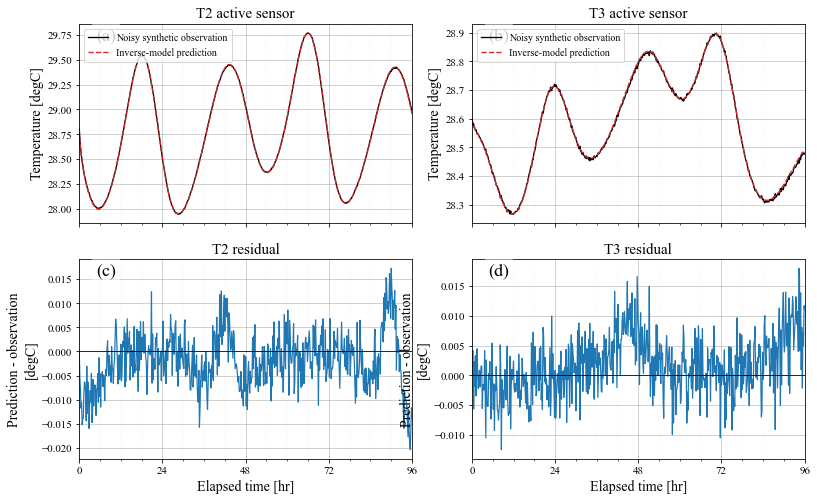

saved temperature diagnostic figure: 00_output_figures/04_synthetic_recovery_time_dependent_alpha/synthetic_temperature_observation_prediction_residual.jpg


In [36]:
fig_temp = plt.figure(figsize=[13, 8])
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.18, hspace=0.18)
spec = gridspec.GridSpec(ncols=2, nrows=2, height_ratios=[1, 1])
ax_t2 = fig_temp.add_subplot(spec[0, 0])
ax_t3 = fig_temp.add_subplot(spec[0, 1], sharex=ax_t2)
ax_r2 = fig_temp.add_subplot(spec[1, 0], sharex=ax_t2)
ax_r3 = fig_temp.add_subplot(spec[1, 1], sharex=ax_t3)

for ax, obs, pred, title in [
    (ax_t2, synthetic_interior_noisy[:, 0], prediction_interior[:, 0], "T2 active sensor"),
    (ax_t3, synthetic_interior_noisy[:, 1], prediction_interior[:, 1], "T3 active sensor"),
]:
    ax.plot(TIME_HOURS, obs, color="black", linewidth=1.3, label="Noisy synthetic observation")
    ax.plot(TIME_HOURS, pred, color="tab:red", linestyle="--", linewidth=1.4, label="Inverse-model prediction")
    ax.set_title(title, fontsize=15)
    ax.set_ylabel("Temperature [degC]", fontsize=14)
    ax.legend(loc="best", fontsize=10, facecolor="white")

ax_r2.plot(TIME_HOURS, residual_interior[:, 0], color="tab:blue", linewidth=1.2)
ax_r3.plot(TIME_HOURS, residual_interior[:, 1], color="tab:blue", linewidth=1.2)
for ax, title in [(ax_r2, "T2 residual"), (ax_r3, "T3 residual")]:
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.set_title(title, fontsize=15)
    ax.set_ylabel("Prediction - observation\n[degC]", fontsize=14)
    ax.set_xlabel("Elapsed time [hr]", fontsize=14)

for jj, ax in enumerate([ax_t2, ax_t3, ax_r2, ax_r3]):
    text_alphabet(ax, alphabet[jj])
    ax.tick_params(axis="both", labelsize=11)
    ax.grid(True, which="major", color="gray", alpha=0.5, linewidth=0.7)
    ax.grid(True, which="minor", color="lightgray", alpha=0.4, linewidth=0.3, linestyle="--")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(24))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(6))

for ax in [ax_t2, ax_t3]:
    ax.tick_params(axis="x", which="both", labelbottom=False)
for ax in [ax_r2, ax_r3]:
    ax.set_xlim(TIME_HOURS[0], TIME_HOURS[-1])

fig_temp.savefig(FIG_TEMPERATURE, dpi=800, bbox_inches="tight")
plt.show()
print("saved temperature diagnostic figure:", FIG_TEMPERATURE)